# E-Commerce Churn Prediction Pipeline
**Problem Statement:** Predicting customer churn in e-commerce using behavioral and transactional data to enable proactive, targeted retention campaigns.

**AI-Assisted Business Questions to Answer:**
1. Does raising a support ticket increase the probability of a customer churning?
2. How do website visits in the last 30 days correlate with churn?
3. What are the top behavioral indicators that a customer is at risk of leaving?

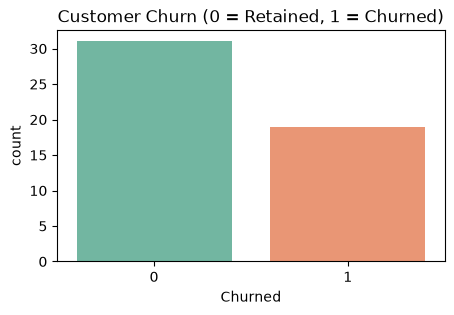

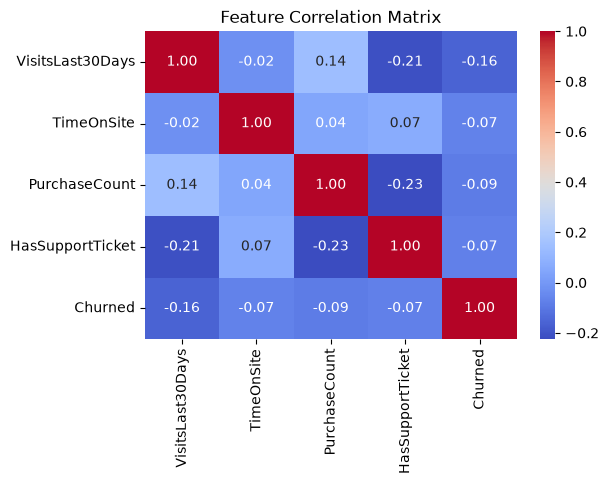


--- Model Results ---
Accuracy Score: 0.5

Classification Report:
               precision    recall  f1-score   support

           0       0.44      1.00      0.62         4
           1       1.00      0.17      0.29         6

    accuracy                           0.50        10
   macro avg       0.72      0.58      0.45        10
weighted avg       0.78      0.50      0.42        10


Top Predictors for Churn:
 TimeOnSite          0.361097
VisitsLast30Days    0.342858
PurchaseCount       0.244651
HasSupportTicket    0.051394
dtype: float64


In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report
import warnings
warnings.filterwarnings('ignore') 

# 1. Data Load & Prepare
df = pd.read_excel('ecommerce_churn.xlsx')
le = LabelEncoder()
df['HasSupportTicket'] = le.fit_transform(df['HasSupportTicket'])
df['Churned'] = le.fit_transform(df['Churned'])

X = df.drop(['UserID', 'Churned'], axis=1)
y = df['Churned']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 2. EDA (Graphs)
plt.figure(figsize=(5,3))
sns.countplot(x='Churned', data=df, palette='Set2')
plt.title('Customer Churn (0 = Retained, 1 = Churned)')
plt.show()

plt.figure(figsize=(6,4))
sns.heatmap(df.drop('UserID', axis=1).corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Feature Correlation Matrix')
plt.show()

# 3. Model Training & Results
model = RandomForestClassifier(random_state=42, n_estimators=100)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print("\n--- Model Results ---")
print("Accuracy Score:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

feature_importances = pd.Series(model.feature_importances_, index=X.columns).sort_values(ascending=False)
print("\nTop Predictors for Churn:\n", feature_importances)

### Conclusion & Business Insights
Based on the Random Forest model evaluation, the top features predicting customer churn are:
1. **TimeOnSite** (36.1% importance)
2. **VisitsLast30Days** (34.2% importance)
3. **PurchaseCount** (24.4% importance)
    
**Actionable Insight for Terno:** 
A customer's engagement level (Time on Site and Visit Frequency) is the strongest indicator of whether they will churn. Interestingly, raising a support ticket had the least impact. The business should set up automated AI alerts to trigger targeted retention campaigns (like personalized emails or discount codes) specifically when a customer's 'TimeOnSite' or 'Visits' drop significantly below their historical average.